# Combining the 10 datasets

In [2]:
import os
import glob
import re
import pandas as pd

In [3]:
import pandas as pd

df_2015 = pd.read_csv("../data/raw/amazon_india_2015.csv")
df_2015.head()

,transaction_id,order_date,customer_id,product_id,product_name,category,subcategory,brand,original_price_inr,discount_percent,...,is_festival_sale,festival_name,customer_rating,return_status,order_month,order_year,order_quarter,product_weight_kg,is_prime_eligible,product_rating
0,TXN_2015_00000001,2015-01-25,CUST_2015_00003884,PROD_000021,Samsung Galaxy S6 16GB Black,Electronics,Smartphones,Samsung,123614.29,27.91,...,True,Republic Day Sale,5.0,Delivered,1,2015,1,0.19,True,4.7
1,TXN_2015_00000002,2015-01-05,CUST_2015_00011709,PROD_000055,OnePlus OnePlus 2 16GB White,Electronics,Smartphones,OnePlus,54731.86,0.00,...,False,NaN,4.5,Delivered,1,2015,1,0.20,True,4.1
2,TXN_2015_00000003,2015-01-24,CUST_2015_00004782,PROD_000039,Samsung Galaxy Note 5 64GB Black,Electronics,Smartphones,Samsung,97644.25,46.93,...,True,Republic Day Sale,NaN,Delivered,1,2015,1,0.17,True,3.3
3,TXN_2015_00000004,2015-01-28,CUST_2015_00008105,PROD_000085,Motorola Moto G (3rd Gen) 16GB Black,Electronics,Smartphones,Motorola,"21,947.26",0.00,...,False,NaN,3.0,Delivered,1,2015,1,0.22,True,3.5
4,TXN_2015_00000005,2015-01-31,CUST_2015_00002955,PROD_000055,OnePlus OnePlus 2 16GB White,Electronics,Smartphones,OnePlus,54731.86,0.00,...,FALSE,NaN,4.0,Delivered,1,2015,1,0.20,True,4.1


In [4]:
import pandas as pd
import os
os.chdir("..")

print(os.getcwd()) 

all_files = []
for year in range(2015, 2026):
    filepath = f"data/raw/amazon_india_{year}.csv"
    df_year = pd.read_csv(filepath)
    df_year['file_year'] = year
    all_files.append(df_year)

c:\Users\Admin\Desktop\Data_Cleaning_Project_2


In [5]:
# Combine all years into one big DataFrame
df = pd.concat(all_files, ignore_index=True)
print(f"Total rows: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

Total rows: 1127609
Total columns: 35


# Data understanding

In [6]:
print(df.columns.tolist())

['transaction_id', 'order_date', 'customer_id', 'product_id', 'product_name', 'category', 'subcategory', 'brand', 'original_price_inr', 'discount_percent', 'discounted_price_inr', 'quantity', 'subtotal_inr', 'delivery_charges', 'final_amount_inr', 'customer_city', 'customer_state', 'customer_tier', 'customer_spending_tier', 'customer_age_group', 'payment_method', 'delivery_days', 'delivery_type', 'is_prime_member', 'is_festival_sale', 'festival_name', 'customer_rating', 'return_status', 'order_month', 'order_year', 'order_quarter', 'product_weight_kg', 'is_prime_eligible', 'product_rating', 'file_year']


In [7]:
print(df.dtypes)

transaction_id             object
order_date                 object
customer_id                object
product_id                 object
product_name               object
category                   object
subcategory                object
brand                      object
original_price_inr         object
discount_percent          float64
discounted_price_inr      float64
quantity                    int64
subtotal_inr              float64
delivery_charges          float64
final_amount_inr          float64
customer_city              object
customer_state             object
customer_tier              object
customer_spending_tier     object
customer_age_group         object
payment_method             object
delivery_days              object
delivery_type              object
is_prime_member            object
is_festival_sale           object
festival_name              object
customer_rating            object
return_status              object
order_month                 int64
order_year    

In [8]:
print(df.head())

      transaction_id  order_date         customer_id   product_id  \
0  TXN_2015_00000001  2015-01-25  CUST_2015_00003884  PROD_000021   
1  TXN_2015_00000002  2015-01-05  CUST_2015_00011709  PROD_000055   
2  TXN_2015_00000003  2015-01-24  CUST_2015_00004782  PROD_000039   
3  TXN_2015_00000004  2015-01-28  CUST_2015_00008105  PROD_000085   
4  TXN_2015_00000005  2015-01-31  CUST_2015_00002955  PROD_000055   

                           product_name     category  subcategory     brand  \
0          Samsung Galaxy S6 16GB Black  Electronics  Smartphones   Samsung   
1          OnePlus OnePlus 2 16GB White  Electronics  Smartphones   OnePlus   
2      Samsung Galaxy Note 5 64GB Black  Electronics  Smartphones   Samsung   
3  Motorola Moto G (3rd Gen) 16GB Black  Electronics  Smartphones  Motorola   
4          OnePlus OnePlus 2 16GB White  Electronics  Smartphones   OnePlus   

  original_price_inr  discount_percent  ...      festival_name  \
0          123614.29             27.91  ... 

In [9]:
print(df.describe())

       discount_percent  discounted_price_inr      quantity  subtotal_inr  \
count      1.127609e+06          1.127609e+06  1.127609e+06  1.127609e+06   
mean       1.742035e+01          5.454134e+04  1.250063e+00  6.818740e+04   
std        2.055377e+01          4.582480e+04  5.365034e-01  6.893407e+04   
min        0.000000e+00          3.443300e+02  1.000000e+00  3.443300e+02   
25%        0.000000e+00          2.278069e+04  1.000000e+00  2.521799e+04   
50%        1.037000e+01          3.800119e+04  1.000000e+00  4.473182e+04   
75%        2.841000e+01          7.410332e+04  1.000000e+00  8.852179e+04   
max        7.000000e+01          4.207048e+05  3.000000e+00  1.262114e+06   

       delivery_charges  final_amount_inr   order_month    order_year  \
count      1.037408e+06      1.127609e+06  1.127609e+06  1.127609e+06   
mean       3.084611e-04      6.818740e+04  6.940627e+00  2.020637e+03   
std        1.110782e-01      6.893407e+04  3.539183e+00  2.690906e+00   
min        0.0

In [10]:
print(df.isnull().sum())

transaction_id                 0
order_date                     0
customer_id                    0
product_id                     0
product_name                   0
category                       0
subcategory                    0
brand                          0
original_price_inr             0
discount_percent               0
discounted_price_inr           0
quantity                       0
subtotal_inr                   0
delivery_charges           90201
final_amount_inr               0
customer_city                  0
customer_state                 0
customer_tier                  0
customer_spending_tier         0
customer_age_group        135315
payment_method                 0
delivery_days                  0
delivery_type                  0
is_prime_member                0
is_festival_sale               0
festival_name             777736
customer_rating           341696
return_status                  0
order_month                    0
order_year                     0
order_quar

In [11]:
# Load the Amazon India products catalog dataset from the CSV file
df_products = pd.read_csv("data/raw/amazon_india_products_catalog.csv")

In [12]:
# Check the number of rows and columns in the products dataset
print(df_products.shape)

(2004, 11)


In [13]:
print(df_products.head())

    product_id               product_name     category  subcategory  brand  \
0  PROD_000001  Apple iPhone 6 16GB Black  Electronics  Smartphones  Apple   
1  PROD_000002  Apple iPhone 6 32GB Black  Electronics  Smartphones  Apple   
2  PROD_000003  Apple iPhone 6 64GB Black  Electronics  Smartphones  Apple   
3  PROD_000004  Apple iPhone 6 16GB White  Electronics  Smartphones  Apple   
4  PROD_000005  Apple iPhone 6 32GB White  Electronics  Smartphones  Apple   

   base_price_2015  weight_kg  rating  is_prime_eligible  launch_year  \
0        190469.10       0.21     3.9               True         2015   
1        158424.89       0.18     3.4               True         2015   
2        118141.16       0.22     4.6               True         2015   
3        211721.16       0.21     4.1               True         2015   
4        114806.24       0.20     3.8               True         2015   

      model  
0  iPhone 6  
1  iPhone 6  
2  iPhone 6  
3  iPhone 6  
4  iPhone 6  


In [14]:
print(df_products.columns.tolist())

['product_id', 'product_name', 'category', 'subcategory', 'brand', 'base_price_2015', 'weight_kg', 'rating', 'is_prime_eligible', 'launch_year', 'model']


In [15]:

print(df_products.dtypes)

product_id            object
product_name          object
category              object
subcategory           object
brand                 object
base_price_2015      float64
weight_kg            float64
rating               float64
is_prime_eligible       bool
launch_year            int64
model                 object
dtype: object


In [16]:
print(df_products.describe())

       base_price_2015    weight_kg       rating  launch_year
count      2004.000000  2004.000000  2004.000000  2004.000000
mean      73099.956751     0.727869     3.918014  2020.167166
std       68490.210618     3.362967     0.452981     3.081761
min         841.750000     0.030000     3.000000  2015.000000
25%       22943.790000     0.180000     3.500000  2018.000000
50%       42182.740000     0.210000     3.900000  2020.000000
75%      106280.612500     0.240000     4.300000  2023.000000
max      323504.370000    44.260000     4.800000  2025.000000


In [17]:
print(df_products.isnull().sum())

product_id           0
product_name         0
category             0
subcategory          0
brand                0
base_price_2015      0
weight_kg            0
rating               0
is_prime_eligible    0
launch_year          0
model                0
dtype: int64


In [18]:
print(df_products)

       product_id               product_name     category         subcategory  \
0     PROD_000001  Apple iPhone 6 16GB Black  Electronics         Smartphones   
1     PROD_000002  Apple iPhone 6 32GB Black  Electronics         Smartphones   
2     PROD_000003  Apple iPhone 6 64GB Black  Electronics         Smartphones   
3     PROD_000004  Apple iPhone 6 16GB White  Electronics         Smartphones   
4     PROD_000005  Apple iPhone 6 32GB White  Electronics         Smartphones   
...           ...                        ...          ...                 ...   
1999  PROD_002000         LG OLED TV Premium  Electronics  TV & Entertainment   
2000  PROD_002001                 LG QLED TV  Electronics  TV & Entertainment   
2001  PROD_002002              LG Android TV  Electronics  TV & Entertainment   
2002  PROD_002003              LG Fire Stick  Electronics  TV & Entertainment   
2003  PROD_002004              LG Chromecast  Electronics  TV & Entertainment   

      brand  base_price_201

# Data Cleaning

In [19]:

import pandas as pd
import os

# Load all year files and combine them
all_files = []
for year in range(2015, 2026):
    filepath = f"data/raw/amazon_india_{year}.csv"
    df_year = pd.read_csv(filepath)
    all_files.append(df_year)

df = pd.concat(all_files, ignore_index=True)
print("Data loaded! Shape:", df.shape)

Data loaded! Shape: (1127609, 34)


In [20]:
# Create a copy of the original dataset for data cleaning
df_clean = df.copy()

# Print a confirmation message and check the copied dataset's shape
print("Copy created! Shape:", df_clean.shape)

Copy created! Shape: (1127609, 34)


In [21]:
df_clean

,transaction_id,order_date,customer_id,product_id,product_name,category,subcategory,brand,original_price_inr,discount_percent,...,is_festival_sale,festival_name,customer_rating,return_status,order_month,order_year,order_quarter,product_weight_kg,is_prime_eligible,product_rating
0,TXN_2015_00000001,2015-01-25,CUST_2015_00003884,PROD_000021,Samsung Galaxy S6 16GB Black,Electronics,Smartphones,Samsung,123614.29,27.91,...,True,Republic Day Sale,5.0,Delivered,1,2015,1,0.19,True,4.7
1,TXN_2015_00000002,2015-01-05,CUST_2015_00011709,PROD_000055,OnePlus OnePlus 2 16GB White,Electronics,Smartphones,OnePlus,54731.86,0.00,...,False,NaN,4.5,Delivered,1,2015,1,0.20,True,4.1
2,TXN_2015_00000003,2015-01-24,CUST_2015_00004782,PROD_000039,Samsung Galaxy Note 5 64GB Black,Electronics,Smartphones,Samsung,97644.25,46.93,...,True,Republic Day Sale,NaN,Delivered,1,2015,1,0.17,True,3.3
3,TXN_2015_00000004,2015-01-28,CUST_2015_00008105,PROD_000085,Motorola Moto G (3rd Gen) 16GB Black,Electronics,Smartphones,Motorola,"21,947.26",0.00,...,False,NaN,3.0,Delivered,1,2015,1,0.22,True,3.5
4,TXN_2015_00000005,2015-01-31,CUST_2015_00002955,PROD_000055,OnePlus OnePlus 2 16GB White,Electronics,Smartphones,OnePlus,54731.86,0.00,...,FALSE,NaN,4.0,Delivered,1,2015,1,0.20,True,4.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1127604,TXN_2025_00019019_DUP,2025-04-07,CUST_2022_00004500,PROD_000136,Samsung Galaxy S7 Edge 16GB Blue,Electronics,Smartphones,Samsung,67658.04,0.00,...,False,NaN,3.5,Delivered,4,2025,2,0.16,True,3.4
1127605,TXN_2025_00053859_DUP,09-10-2025,CUST_2025_00013666,PROD_000527,Samsung Galaxy A50 64GB White,Electronics,Smartphones,Samsung,19905.88,24.29,...,False,NaN,3.5 stars,Delivered,10,2025,4,0.20,False,4.2
1127606,TXN_2025_00030006_DUP,2025-06-29,CUST_2025_00011941,PROD_000839,Samsung Galaxy Note 21 256GB White,Electronics,Smartphones,Samsung,75655.18,30.26,...,True,Back to School,4.0,Delivered,6,2025,2,0.22,True,4.1
1127607,TXN_2025_00066716_DUP,2025-11-21,CUST_2025_00000199,PROD_001581,ASUS Gaming 4GB RAM Black,Electronics,Laptops,ASUS,125461.24,0.00,...,False,NaN,4.5,Delivered,11,2025,4,2.57,False,3.0


## Missing values handling

In [22]:
print(df_clean.isnull().sum())

transaction_id                 0
order_date                     0
customer_id                    0
product_id                     0
product_name                   0
category                       0
subcategory                    0
brand                          0
original_price_inr             0
discount_percent               0
discounted_price_inr           0
quantity                       0
subtotal_inr                   0
delivery_charges           90201
final_amount_inr               0
customer_city                  0
customer_state                 0
customer_tier                  0
customer_spending_tier         0
customer_age_group        135315
payment_method                 0
delivery_days                  0
delivery_type                  0
is_prime_member                0
is_festival_sale               0
festival_name             777736
customer_rating           341696
return_status                  0
order_month                    0
order_year                     0
order_quar

In [23]:
print(df_clean.shape)

(1127609, 34)


In [24]:
# Display only the columns that contain null values and their null counts
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

delivery_charges       90201
customer_age_group    135315
festival_name         777736
customer_rating       341696
dtype: int64


In [25]:
df_clean['delivery_charges'].unique()

array([ 0., nan, 40.])

In [26]:
df_clean['delivery_charges'].dtype

dtype('float64')

In [27]:
# Check the frequency of each delivery charge value, including missing values
print(df_clean["delivery_charges"].value_counts(dropna=False))

delivery_charges
0.0     1037400
NaN       90201
40.0          8
Name: count, dtype: int64


In [28]:
# Fill missing delivery charges with 0.0 for free delivery
df_clean['delivery_charges'] = df_clean['delivery_charges'].fillna(0.0)

In [29]:
df_clean['delivery_charges'].unique()

array([ 0., 40.])

In [30]:
df_clean['festival_name'].unique()

array(['Republic Day Sale', nan, 'Valentine Sale', 'Holi Festival',
       'Summer Sale', 'Back to School', 'Prime Day',
       'Amazon Great Indian Festival', 'Diwali Sale'], dtype=object)

In [31]:
# Check the frequency of each festival name value, including missing values
print(df_clean["festival_name"].value_counts(dropna=False))

festival_name
NaN                             777736
Back to School                   85396
Diwali Sale                      83611
Amazon Great Indian Festival     53062
Summer Sale                      44931
Holi Festival                    39608
Republic Day Sale                20183
Valentine Sale                   14106
Prime Day                         8976
Name: count, dtype: int64


In [32]:
# Fill missing festival names with 'No Festival' to represent regular days
df_clean['festival_name'] = df_clean['festival_name'].fillna('No Festival')

In [33]:
df_clean['festival_name'].unique()

array(['Republic Day Sale', 'No Festival', 'Valentine Sale',
       'Holi Festival', 'Summer Sale', 'Back to School', 'Prime Day',
       'Amazon Great Indian Festival', 'Diwali Sale'], dtype=object)

In [34]:
df_clean['festival_name'].isnull().sum()

np.int64(0)

In [35]:
# Display only the columns that contain null values and their null counts
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

customer_age_group    135315
customer_rating       341696
dtype: int64


In [36]:
df['customer_rating'].unique()


array(['5.0', '4.5', nan, '3.0', '4.0', '3.5', '4/5', '5.0 stars',
       '5.0/5.0', '4.5 stars', '3.5/5.0', '3/5', '4', '4.0 stars',
       '4.5/5.0', '5', '5/5', '4.0/5.0', '3.5 stars', '3.0 stars', '3',
       '3.0/5.0'], dtype=object)

In [37]:
# Step 1: Extract just the rating number from the messy text
df_clean['customer_rating'] = df_clean['customer_rating'].astype(str).str.extract(r'(\d+(?:\.\d+)?)')[0]

# Step 2: Convert those text numbers into real math numbers
df_clean['customer_rating'] = pd.to_numeric(df_clean['customer_rating'], errors='coerce')

In [38]:
df_clean['customer_rating'].unique()

array([5. , 4.5, nan, 3. , 4. , 3.5])

In [39]:
# Calculate the mean (average) of the customer ratings and fill the missing blanks
mean_rating = df_clean['customer_rating'].mean()
df_clean['customer_rating'] = df_clean['customer_rating'].fillna(mean_rating)

# Round ratings to one decimal place
df_clean['customer_rating'] = df_clean['customer_rating'].round(1)

In [40]:
df_clean['customer_rating'].unique()

array([5. , 4.5, 4.3, 3. , 4. , 3.5])

In [41]:
# Check how many missing values are left in customer_rating (should be 0)
print(df_clean['customer_rating'].isna().sum())

0


In [42]:
# Check how many missing values are left in customer_rating (should be 0)
print(df_clean['customer_rating'].isnull().sum())

0


In [43]:
df_clean['customer_age_group'].unique()

array(['46-55', '26-35', '36-45', '18-25', nan, '55+'], dtype=object)

In [44]:
# Step 1: Find the most common age group for each product ID
product_age_mode = (
    df_clean.dropna(subset=['customer_age_group'])
    .groupby('product_id')['customer_age_group']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else '26-35')
)

# Step 2: Fill the missing blanks using that product's typical age group
df_clean['customer_age_group'] = df_clean['customer_age_group'].fillna(
    df_clean['product_id'].map(product_age_mode)
)

# Step 3: If any blanks are still left over, fill them with the overall favorite age group
df_clean['customer_age_group'] = df_clean['customer_age_group'].fillna(
    df_clean['customer_age_group'].mode()[0]
)

In [45]:
df_clean['customer_age_group'].unique()

array(['46-55', '26-35', '36-45', '18-25', '55+'], dtype=object)

In [46]:
# Check how many missing values are left in customer_rating (should be 0)
print(df_clean['customer_rating'].isnull().sum())

0


In [47]:
print(df_clean.isnull().sum().sum())

0


## Data cleaning Questions


### Question 1

In [48]:
df_clean.shape

(1127609, 34)

In [49]:
df_clean['order_date'] = pd.to_datetime(df_clean['order_date'], errors='coerce', dayfirst=True)
df_clean['order_date'] = df_clean['order_date'].dt.strftime('%Y-%m-%d')

C:\Users\Admin\AppData\Local\Temp\ipykernel_18524\2314464406.py:1: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  df_clean['order_date'] = pd.to_datetime(df_clean['order_date'], errors='coerce', dayfirst=True)


In [50]:
df_clean['order_date'].sample(n=20,random_state=42)

507695     2020-11-13
57977             NaN
611698     2021-08-06
473805     2020-08-23
977189     2024-06-14
427011     2020-04-21
1080493    2025-06-27
817142     2023-02-23
308113     2019-05-31
666542     2021-12-29
858471     2023-06-19
789075     2022-12-04
983605     2024-06-15
736352     2022-07-23
172305     2018-01-16
882538     2023-09-13
761130     2022-10-27
349083     2019-10-02
297022     2019-04-11
165724     2017-09-24
Name: order_date, dtype: object

In [51]:
# Count invalid dates that were converted to NaT
df['order_date'].isnull().sum()

np.int64(0)

### Question 2

In [52]:


# Removing ₹ symbol, commas, converting to float


df_clean['original_price_inr'] = (df_clean['original_price_inr']
    .astype(str)
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip())

# "Price on Request" and other text becomes NaN
df_clean['original_price_inr'] = pd.to_numeric(df_clean['original_price_inr'], errors='coerce')

### Question 3

In [53]:
df_clean['customer_rating'].unique()

array([5. , 4.5, 4.3, 3. , 4. , 3.5])

### Question 4

In [54]:
# Check the unique city names
df_clean['customer_city'].unique()

array(['Mumbai', 'Allahabad', 'Kolkata', 'Ludhiana', 'Delhi', 'Lucknow',
       'Jaipur', 'Bhubaneswar', 'Ahmedabad', 'Bangalore', 'Pune', 'Kochi',
       'Chennai', 'Nagpur', 'Visakhapatnam', 'mumba', 'Gorakhpur',
       'Bombay', 'Kanpur', 'Chandigarh', 'Hyderabad', 'Aligarh', 'Indore',
       'Patna', 'Meerut', 'Coimbatore', 'Vadodara', 'Saharanpur',
       'Bareilly', 'BANGALORE', 'Moradabad', 'New Delhi', 'Surat',
       'KOLKATA', 'Banglore', 'Madras', 'chenai', 'Delhi NCR', 'Varanasi',
       'Bengalore', 'Bengaluru', 'MUMBAI', 'Kolkata ', 'Calcutta',
       'delhi', 'CHENNAI', 'Chennai ', 'kolkata', 'Mumbai ', 'DELHI'],
      dtype=object)

In [55]:
# 1. Strip any accidental spaces and make sure formatting is standard
df_clean['customer_city'] = df_clean['customer_city'].str.strip()

# 2. See all the unique city names in the column
print("Unique City Names:")
print(df_clean['customer_city'].unique())

# 3. Count how many total unique cities there are
print("\nTotal Number of Unique Cities:")
print(df_clean['customer_city'].nunique())

Unique City Names:
['Mumbai' 'Allahabad' 'Kolkata' 'Ludhiana' 'Delhi' 'Lucknow' 'Jaipur'
 'Bhubaneswar' 'Ahmedabad' 'Bangalore' 'Pune' 'Kochi' 'Chennai' 'Nagpur'
 'Visakhapatnam' 'mumba' 'Gorakhpur' 'Bombay' 'Kanpur' 'Chandigarh'
 'Hyderabad' 'Aligarh' 'Indore' 'Patna' 'Meerut' 'Coimbatore' 'Vadodara'
 'Saharanpur' 'Bareilly' 'BANGALORE' 'Moradabad' 'New Delhi' 'Surat'
 'KOLKATA' 'Banglore' 'Madras' 'chenai' 'Delhi NCR' 'Varanasi' 'Bengalore'
 'Bengaluru' 'MUMBAI' 'Calcutta' 'delhi' 'CHENNAI' 'kolkata' 'DELHI']

Total Number of Unique Cities:
47


In [56]:
# Map inconsistent city names to one standard city name
city_mapping = {
    'mumba': 'Mumbai',
    'Bombay': 'Mumbai',
    'MUMBAI': 'Mumbai',
    'Mumbai ': 'Mumbai',

    'BANGALORE': 'Bangalore',
    'Banglore': 'Bangalore',
    'Bengalore': 'Bangalore',
    'Bengaluru': 'Bangalore',

    'KOLKATA': 'Kolkata',
    'Kolkata ': 'Kolkata',
    'Calcutta': 'Kolkata',
    'kolkata': 'Kolkata',

    'New Delhi': 'Delhi',
    'Delhi NCR': 'Delhi',
    'delhi': 'Delhi',
    'DELHI': 'Delhi',

    'Madras': 'Chennai',
    'chenai': 'Chennai',
    'CHENNAI': 'Chennai',
    'Chennai ': 'Chennai'
}

In [57]:
# 2. See all the unique city names in the column
print("Unique City Names:")
print(df_clean['customer_city'].unique())

# 3. Count how many total unique cities there are
print("\nTotal Number of Unique Cities:")
print(df_clean['customer_city'].nunique())

Unique City Names:


['Mumbai' 'Allahabad' 'Kolkata' 'Ludhiana' 'Delhi' 'Lucknow' 'Jaipur'
 'Bhubaneswar' 'Ahmedabad' 'Bangalore' 'Pune' 'Kochi' 'Chennai' 'Nagpur'
 'Visakhapatnam' 'mumba' 'Gorakhpur' 'Bombay' 'Kanpur' 'Chandigarh'
 'Hyderabad' 'Aligarh' 'Indore' 'Patna' 'Meerut' 'Coimbatore' 'Vadodara'
 'Saharanpur' 'Bareilly' 'BANGALORE' 'Moradabad' 'New Delhi' 'Surat'
 'KOLKATA' 'Banglore' 'Madras' 'chenai' 'Delhi NCR' 'Varanasi' 'Bengalore'
 'Bengaluru' 'MUMBAI' 'Calcutta' 'delhi' 'CHENNAI' 'kolkata' 'DELHI']

Total Number of Unique Cities:
47


### Question 5

In [58]:
# Check unique values for the three boolean columns
print("is_prime_member unique:", df_clean['is_prime_member'].unique())
print("is_prime_eligible unique:", df_clean['is_prime_eligible'].unique())
print("is_festival_sale unique:", df_clean['is_festival_sale'].unique())

is_prime_member unique: ['No' 'False' 'FALSE' '0' 'True' '1' 'TRUE' 'Yes']
is_prime_eligible unique: ['True' 'No' 'False' 'TRUE' '1' 'Yes' '0' 'FALSE']
is_festival_sale unique: ['True' 'False' 'FALSE' 'No' '0' '1' 'Yes' 'TRUE']


In [59]:
# Check the data types of the three boolean columns
print(df_clean[['is_prime_member', 'is_prime_eligible', 'is_festival_sale']].dtypes)

is_prime_member      object
is_prime_eligible    object
is_festival_sale     object
dtype: object


In [60]:
# Dictionary to map messy values into real boolean values
bool_mapping = {
    'True': True, 'TRUE': True, '1': True, 'Yes': True,
    'False': False, 'FALSE': False, '0': False, 'No': False
}

# List of the 3 columns
boolean_columns = ['is_prime_member', 'is_prime_eligible', 'is_festival_sale']

# Replace the text words and convert them into true boolean types
for col in boolean_columns:
    df_clean[col] = df_clean[col].replace(bool_mapping).astype(bool)

C:\Users\Admin\AppData\Local\Temp\ipykernel_18524\2192326771.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean[col] = df_clean[col].replace(bool_mapping).astype(bool)
C:\Users\Admin\AppData\Local\Temp\ipykernel_18524\2192326771.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_clean[col] = df_clean[col].replace(bool_mapping).astype(bool)
C:\Users\Admin\AppData\Local\Temp\ipykernel_18524\2192326771.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To ret

In [61]:
# Check unique values for the three boolean columns
print("is_prime_member unique:", df_clean['is_prime_member'].unique())
print("is_prime_eligible unique:", df_clean['is_prime_eligible'].unique())
print("is_festival_sale unique:", df_clean['is_festival_sale'].unique())

is_prime_member unique: [False  True]
is_prime_eligible unique: [ True False]
is_festival_sale unique: [ True False]


### Question 6

In [62]:
# Check all unique category names
print("Unique Categories:")
print(df_clean['category'].unique())

# Check how many unique categories exist in total
print("\nTotal Unique Count:", df_clean['category'].nunique())


Unique Categories:
['Electronics' 'ELECTRONICS' 'Electronics & Accessories' 'Electronic'
 'Electronicss']

Total Unique Count: 5


In [63]:
# 1. Create the mapping dictionary for your category variations
category_mapping = {
    'ELECTRONICS': 'Electronics',
    'Electronics & Accessories': 'Electronics',
    'Electronic': 'Electronics',
    'Electronicss': 'Electronics'
}

# 2. Apply the replacement using the 'category' column
df_clean['category'] = df_clean['category'].replace(category_mapping)

# 3. Verify the fix by checking unique values and count again
print("Updated Unique Categories:", df_clean['category'].unique())
print("Updated Total Unique Count:", df_clean['category'].nunique())

Updated Unique Categories: ['Electronics']
Updated Total Unique Count: 1


### Question 7

In [64]:
# Check the data type and unique values in delivery_days
print(df_clean['delivery_days'].dtype)
print(df_clean['delivery_days'].unique())

object
['6' '4' '3' '5' '7' 'Express' '0' '-1' 'Same Day' '1-2 days' '15' '1' '2']


In [65]:
print(sorted(df_clean['delivery_days'].unique()))

['-1', '0', '1', '1-2 days', '15', '2', '3', '4', '5', '6', '7', 'Express', 'Same Day']


In [66]:
import numpy as np

# 1. Your mapping dictionary
delivery_mapping = {
    'Same Day': 0,
    'Express': 1,      
    '1-2 days': 2,     
    '-1': np.nan       
}

# Apply mapping
df_clean['delivery_days'] = df_clean['delivery_days'].replace(delivery_mapping)

# 2. Convert to numeric
df_clean['delivery_days'] = pd.to_numeric(df_clean['delivery_days'], errors='coerce')

# 3. Handle unrealistic values: Anything less than 0 or greater than 7 becomes NaN
df_clean.loc[(df_clean['delivery_days'] < 0) | (df_clean['delivery_days'] > 7), 'delivery_days'] = np.nan

# 4. Fill missing values with the median delivery days
median_days = df_clean['delivery_days'].median()
df_clean['delivery_days'] = df_clean['delivery_days'].fillna(median_days)

# 5. Convert to integer format
df_clean['delivery_days'] = df_clean['delivery_days'].astype(int)

# 6. Verify the final unique values and data type
print("Cleaned delivery_days unique values:")
print(df_clean['delivery_days'].unique())
print("\nData Type:", df_clean['delivery_days'].dtype)

Cleaned delivery_days unique values:
[6 4 3 5 7 1 0 2]

Data Type: int64


In [67]:
print("Missing values:", df_clean['delivery_days'].isna().sum())

Missing values: 0


### Question 8

In [69]:

df_clean = df_clean.drop_duplicates()

suspicious = df_clean.duplicated(subset=['customer_id', 'product_id', 'order_date', 'final_amount_inr'], keep=False)
print(f"Suspicious duplicates: {suspicious.sum()}")
df_clean['is_potential_duplicate'] = suspicious

Suspicious duplicates: 11222


### Question 9

<Axes: ylabel='original_price_inr'>

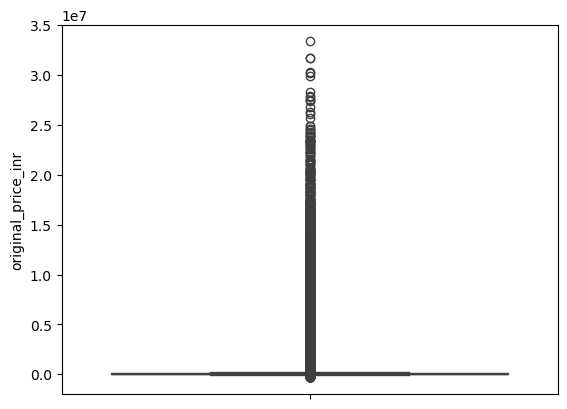

In [70]:

import matplotlib.pyplot as plt
import seaborn as sns
sns.boxplot(df_clean['original_price_inr'])

In [71]:
Q1 = df_clean['original_price_inr'].quantile(0.25)
Q3 = df_clean['original_price_inr'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 3 * IQR

df_clean.loc[df_clean['original_price_inr'] > upper_bound, 'original_price_inr'] = None

### Question 10

In [73]:
# Check all unique payment method values
df_clean['payment_method'].unique()

array(['COD', 'Debit Card', 'Credit Card', 'Net Banking', 'UPI', 'Wallet',
       'BNPL'], dtype=object)

In [74]:
df_clean['payment_method'].value_counts()

payment_method
UPI            384228
COD            322831
Credit Card    172261
Debit Card     140202
Net Banking     64971
Wallet          22821
BNPL            20295
Name: count, dtype: int64

In [76]:
df_clean['payment_method'].head()

0    COD
1    COD
2    COD
3    COD
4    COD
Name: payment_method, dtype: object

In [ ]:
# 1. Define the filename for your cleaned dataset
output_file_path = 'amazon_india_cleaned.csv'

# 2. Export the DataFrame to a CSV file
# index=False ensures Pandas doesn't save the row numbers as an extra, unnecessary column
df_clean.to_csv(output_file_path, index=False)

print(f"Dataset successfully saved as '{output_file_path}'!")

Dataset successfully saved as 'amazon_india_cleaned.csv'!
